<a href="https://colab.research.google.com/github/handanaltuner/veri-bilimi-calisma-notlari/blob/main/Tech_%C4%B0stanbul_4_Odev__Handan_Altuner.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive


In [ ]:
veri_yolu="/content/drive/MyDrive/Techİstanbul/ogrenci_calisma_notlari.csv"

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
!pip install numpy
!pip install pandas
!pip install matplotlib

In [ ]:
veri = pd.read_csv(veri_yolu)

Eğim: 5.891397399679669
Kesişim Noktası: 23.66668954314231


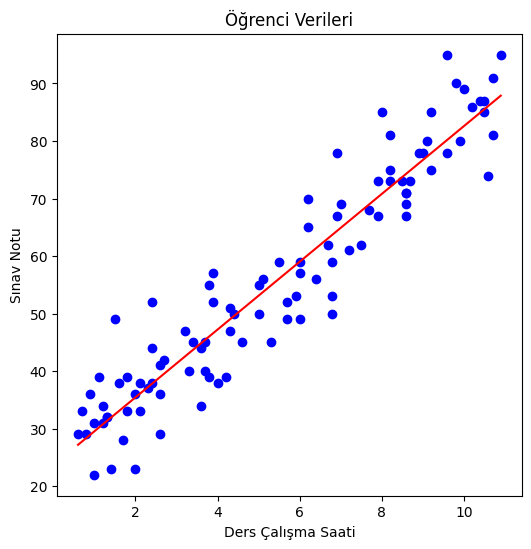

In [ ]:
plt.figure(figsize=(6,6))

plt.scatter(veri['calisma_saati'], veri['sinav_notu'], color='blue')
plt.title('Öğrenci Verileri')
plt.xlabel('Ders Çalışma Saati')
plt.ylabel('Sınav Notu')


#regresyon eğrisi

egim, kesisim=np.polyfit(veri['calisma_saati'], veri['sinav_notu'], 1)
plt.plot(veri['calisma_saati'], egim*veri['calisma_saati']+kesisim, color='red')

print("Eğim:", egim)
print("Kesişim Noktası:", kesisim)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


from sklearn.metrics import mean_squared_error

In [ ]:
#X=veri,[['calisöa_saati']] de yazılabilirdi. İkisi de aynı

X=veri['calisma_saati'].values.reshape(-1,1)

Y=veri['sinav_notu']


In [ ]:
X_egitim, X_test, Y_egitim, Y_test= train_test_split(X,Y, test_size=0.2, random_state=42)

In [ ]:
model=LinearRegression()

In [ ]:
model.fit(X_egitim, Y_egitim)

LinearRegression()

In [ ]:
Y_tahmin=model.predict(X_test)

MSE HESABI

In [ ]:
mse=mean_squared_error(Y_test, Y_tahmin)
print("MSE hata skoru: ", mse)


MSE hata skoru:  34.94174063316996


KATSAYILAR VE KESİŞİM NOKTASI

In [ ]:
print("Katsayılar:" ,model.coef_)
print("Kesişim Noktası:", model.intercept_)

Katsayılar: [5.94099838]
Kesişim Noktası: 23.6559177638527


<function matplotlib.pyplot.show(close=None, block=None)>

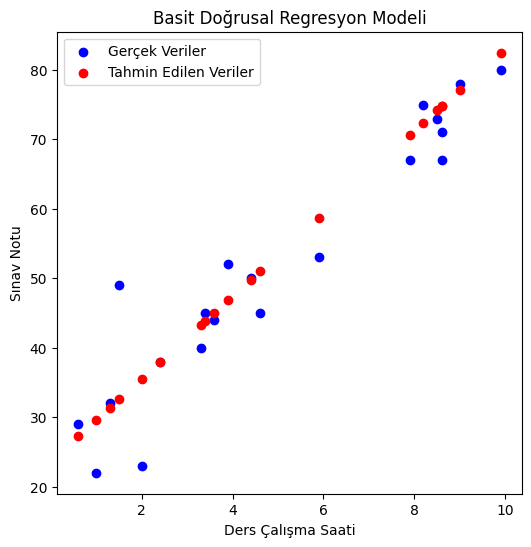

In [ ]:
plt.figure(figsize=(6,6))

plt.scatter(X_test, Y_test, color='blue', label='Gerçek Veriler')
plt.scatter(X_test, Y_tahmin, color='red', label='Tahmin Edilen Veriler')

plt.title("Basit Doğrusal Regresyon Modeli")
plt.xlabel("Ders Çalışma Saati")
plt.ylabel("Sınav Notu")
plt.legend()
plt.show


In [ ]:
egim=model.coef_[0]
kesisim=model.intercept_
mse=mean_squared_error(Y_test, Y_tahmin)
rmse=mse ** 0.5
r2=model.score(X_test, Y_test)

print(f"Eğim (b)   : {egim:.2f}")
print(f"Kesişim (a): {kesisim:.2f}")
print(f"MSE        : {mse:.2f}")
print(f"RMSE       : {rmse:.2f}")
print(f"R^2 (test) : {r2:.2f}")

Eğim (b)   : 5.94
Kesişim (a): 23.66
MSE        : 34.94
RMSE       : 5.91
R^2 (test) : 0.89
